# 11 · Full-field play viewer: the whole play, with the linemen in focus
**DS 5110 Big Data Systems — Final Project: Trench Play (OL and DL)**

**What this notebook does**
Animates complete NFL plays on a regulation field — yard lines, numbers, hashes, end zones, line of scrimmage, first-down line, down marker, clock, score and the play-by-play text — so the offensive and defensive linemen can be watched **in the context of the play**: where the ball went, who threw or carried it, whether the pocket broke down.

**What is drawn, and where it comes from**

| On the field | Source |
|---|---|
| **Solid dots** (red offense / blue defense) | real 10 Hz tracking of every rookie on the play (any position) |
| **Yellow ring** | the play's **focus lineman**: the DL who got pressure / the sack / the tackle, or the OL at the run's gap / the pass protector |
| **Hollow dots** (QB, ball carrier, receiver) | **reconstructed from the play-by-play**: formation (shotgun / under center depth), event times in the tracking (`ball_snap`, `handoff`, `pass_forward`, `pass_arrived`, `qb_sack`, `tackle`), the run gap, pass direction and air yards, yards gained, sack spot. When the receiver is himself a tracked rookie, his real track is used. |
| **Ball** (brown) | follows the same reconstruction: snap → QB → throw to the catch / landing spot, or handoff → runner → end of the run |

Why the reconstruction: the 2027 Big Data Bowl tracking covers **only the 510 rookies of the 2023–25 draft classes** (there are no rookie QBs or RBs among them, and no ball row). No public data set has all 22 players for these seasons, so the rest of the play is rebuilt from what the play-by-play records. Reconstructed objects are approximate and labelled "est." everywhere.

Beside the field a **live panel** shows, for every tracked OL and DL: speed, ground covered since the snap, the moment he passes 1 yard (in-game first step), get-off (DL), his Combine trait percentiles (first step, lateral agility, burst — notebook 03) and the rep's outcome (pressure / sack / tackle, pressure allowed, run-gap credit and run success). Below the field, the linemen's speed traces with a moving time cursor.

Five plays are chosen automatically (same rules every run):
| Name | Rule (most tracked rookie linemen wins) |
|---|---|
| `pressure_incomplete` | pass incomplete after a rookie DL got pressure |
| `sack` | a rookie DL sack |
| `pass_block_clean` | completed pass, at least two rookie OL, none allowed pressure |
| `run_block_credit` | run of 4+ yards where a rookie OL had full gap credit and the run succeeded |
| `run_stuff` | run of ≤ 1 yard where a rookie DL made the tackle |

**Outputs:** `outputs/play_viewer/<play>.html` (interactive: Play / ½ speed / Pause, slider, hover, drag to zoom; self-contained, opens offline), `outputs/animations/field_<play>.mp4` + `field_<play>_snap.png` (slides), `outputs/tables/11_selected_plays.csv`.
**Inputs:** raw `game_tracking_*.csv`, `player_play.csv`, `players.csv`, `games.csv`; `processed/line_player_play.parquet`, `ingame_snaps.parquet`, `trait_indices.parquet`, `line_players.parquet`.
Needs `plotly` and `imageio-ffmpeg` (`pip install --user plotly imageio-ffmpeg`).

In [1]:
import sys, shutil, re, warnings
warnings.filterwarnings("ignore", message="This pattern is interpreted as a regular expression")
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np, pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib import animation, patches
from IPython.display import display, Image
from pyspark.sql import functions as F
from pyspark.sql.window import Window
from pyspark.sql.types import StructType, StructField, IntegerType, LongType, DoubleType, StringType
import config as C

spark = C.get_spark("11_play_viewer")
VIEW_DIR = C.OUTPUT_DIR / "play_viewer"; VIEW_DIR.mkdir(parents=True, exist_ok=True)
ANIM_DIR = C.OUTPUT_DIR / "animations"; ANIM_DIR.mkdir(parents=True, exist_ok=True)
try:
    import plotly.graph_objects as go
    HAVE_PLOTLY = True
except ImportError:
    HAVE_PLOTLY = False
try:
    import imageio_ffmpeg
    plt.rcParams["animation.ffmpeg_path"] = imageio_ffmpeg.get_ffmpeg_exe()
    HAVE_FFMPEG = True
except ImportError:
    HAVE_FFMPEG = shutil.which("ffmpeg") is not None
print("plotly:", HAVE_PLOTLY, "| video:", "mp4" if HAVE_FFMPEG else "gif")

FIELD, FIELD2, ENDZONE, LINE = "#1f8f3a", "#1b8234", "#14672a", "#ffffff"
OFF, DEF, LOS_C, FD_C, MARK_C, BALL_C, FOCUS_C = "#e8322f", "#1f5fd6", "#2b6cff", "#ffe600", "#ff8a00", "#8b4513", "#ffd400"
POST_SNAP_S = 7.0
GAP_RE = r"(left end|left tackle|left guard|up the middle|right guard|right tackle|right end)"
PASS_RE = r"pass (?:incomplete )?(short|deep) (left|middle|right)"
NAME = r"([A-Z][a-z]{0,3}\.\s?[A-Z][A-Za-z'\-]+(?:\s(?:Jr|Sr|II|III)\.?)?)"

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


/apps/software/standard/core/spark/4.2.0/python/pyspark/testing/utils.py:127: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


26/11/26 22:27:06 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


plotly: True | video: mp4


## 1. Choose the plays (Spark)

In [2]:
I_, L_, D_, S_ = IntegerType(), LongType(), DoubleType(), StringType()
GT_SCHEMA = StructType([StructField(n, t, True) for n, t in [("game_id", L_), ("play_id", I_), ("nfl_id", I_), ("time", S_),
    ("x", D_), ("y", D_), ("s", D_), ("a", D_), ("dis", D_), ("o", D_), ("dir", D_), ("event", S_)]])
raw_gt = spark.read.option("header", True).option("nullValue", "NA").schema(GT_SCHEMA).csv(C.game_tracking_files())
per_play = raw_gt.groupBy("game_id", "play_id").agg(F.countDistinct("nfl_id").alias("n_rookies"))

pp = spark.read.parquet(C.p("line_player_play.parquet")).filter(
    (F.col("season_type") == "REG") & (F.coalesce(F.col("play_nullified_by_penalty"), F.lit("N")) != "Y") & F.col("down").between(1, 4))
ing = spark.read.parquet(C.p("ingame_snaps.parquet")).select("game_id", "play_id", "nfl_id", "slot", "credit", "run_success")
L = (pp.join(ing, ["game_id", "play_id", "nfl_id"], "left")
       .select("game_id", "play_id", "nfl_id", "line_group", "slot", "credit", "run_success", "pass_result", "yards_gained",
               "play_description", "time_to_pressure", "time_to_qb_hurry", "sack", "tackle", "pressure_allowed",
               "player_get_off", "offense_formation")
       .withColumn("pressure", F.col("time_to_pressure").isNotNull() | F.col("time_to_qb_hurry").isNotNull()
                               | (F.coalesce(F.col("sack"), F.lit(0)) > 0))
       .cache())
is_ol, is_dl = F.col("line_group") == "OL", F.col("line_group") == "DL"
plays = (L.groupBy("game_id", "play_id").agg(          # one row per play, all in Spark
            F.sum(is_ol.cast("int")).alias("n_ol"), F.sum(is_dl.cast("int")).alias("n_dl"),
            F.first("pass_result", ignorenulls=True).alias("pass_result"),
            F.first("yards_gained", ignorenulls=True).alias("yards"),
            F.first("play_description", ignorenulls=True).alias("desc"),
            F.first("offense_formation", ignorenulls=True).alias("formation"),
            # every rookie OL on the play kept the QB clean (used for the clean pass-block play)
            F.min(F.when(is_ol, F.when(F.col("pressure_allowed") == False, 1).otherwise(0))).alias("ol_all_clean"))
         .join(per_play, ["game_id", "play_id"])
         .withColumn("n_line", F.col("n_ol") + F.col("n_dl"))
         .withColumn("has_pass_dir", F.coalesce(F.col("desc").rlike(PASS_RE), F.lit(False)))
         .withColumn("has_gap", F.coalesce(F.col("desc").rlike(GAP_RE), F.lit(False)))
         .filter(F.col("formation").isNotNull() & F.col("desc").isNotNull()
                 & ~F.col("desc").rlike("(?i)PENALTY|FUMBLE|Direct snap|Aborted"))
         .cache())

def focus_candidates(cond):
    """One focus lineman per play: the lowest nfl_id among the rookies meeting `cond` (deterministic)."""
    return L.filter(cond).groupBy("game_id", "play_id").agg(F.min("nfl_id").alias("focus_id"))

no_sack = F.coalesce(F.col("sack"), F.lit(0)) == 0
rules = {
    "pressure_incomplete": ((F.col("pass_result") == "I") & F.col("has_pass_dir"),
                            focus_candidates(is_dl & F.col("pressure") & no_sack)),
    "sack": ((F.col("pass_result") == "S") & F.col("desc").contains("sacked at"),
             focus_candidates(is_dl & ~no_sack)),
    "pass_block_clean": ((F.col("pass_result") == "C") & F.col("has_pass_dir") & (F.col("n_ol") >= 2) & (F.col("ol_all_clean") == 1),
                         focus_candidates(is_ol & (F.col("pressure_allowed") == False))),
    "run_block_credit": (F.col("pass_result").isNull() & F.col("has_gap") & (F.col("yards") >= 4),
                         focus_candidates(is_ol & (F.col("credit") == 1) & (F.col("run_success") == 1))),
    "run_stuff": (F.col("pass_result").isNull() & F.col("has_gap") & (F.col("yards") <= 1),
                  focus_candidates(is_dl & (F.coalesce(F.col("tackle"), F.lit(0)) > 0))),
}
chosen, used = [], []
for name, (cond, focus) in rules.items():
    c = plays.filter(cond).join(focus, ["game_id", "play_id"])
    for g_, p_ in used:                                   # a play is shown once
        c = c.filter(~((F.col("game_id") == g_) & (F.col("play_id") == p_)))
    r = c.orderBy(F.col("n_line").desc(), F.col("n_rookies").desc(), "game_id", "play_id").first()   # most linemen tracked
    if r is None: print("no play for", name); continue
    used.append((r.game_id, r.play_id))
    chosen.append(dict(name=name, game_id=int(r.game_id), play_id=int(r.play_id), focus_id=int(r.focus_id),
                       n_rookies=int(r.n_rookies), n_ol=int(r.n_ol), n_dl=int(r.n_dl), desc=r.desc))
chosen = pd.DataFrame(chosen)
chosen[["name", "game_id", "play_id", "n_rookies", "n_ol", "n_dl", "desc"]]

,name,game_id,play_id,n_rookies,n_ol,n_dl,desc
0,pressure_incomplete,2025110911,2015,9,4,2,(:12) (Shotgun) A.Rodgers pass incomplete deep...
1,sack,2025110911,2459,9,4,2,(9:28) (Shotgun) A.Rodgers sacked at PIT 27 fo...
2,pass_block_clean,2025092112,1592,10,2,4,(2:08) M.Jones pass short left to C.McCaffrey ...
3,run_block_credit,2024092905,3892,7,3,3,(5:57) (Shotgun) J.Fields up the middle to PIT...
4,run_stuff,2025092112,2883,7,2,4,(1:06) C.McCaffrey right guard to ARZ 1 for no...


## 2. Pull everything about those plays

In [3]:
keys = spark.createDataFrame(chosen[["game_id", "play_id"]].astype({"game_id": "int64", "play_id": "int32"}))
frames = raw_gt.join(F.broadcast(keys), ["game_id", "play_id"]).toPandas()
frames["ts"] = pd.to_datetime(frames.time)
pp_raw = (spark.read.option("header", True).option("nullValue", "NA").option("multiLine", True).option("escape", '"')
          .csv(C.raw("player_play.csv"))
          .withColumn("game_id", F.col("game_id").cast("long")).withColumn("play_id", F.col("play_id").cast("int"))
          .join(F.broadcast(keys), ["game_id", "play_id"]).toPandas()).replace("", np.nan)
pp_raw["nfl_id"] = pp_raw.nfl_id.astype(int)
for c in ["quarter", "down", "yards_to_go", "yardline_number", "pre_snap_home_score", "pre_snap_visitor_score", "yards_gained",
          "pass_length", "expected_points_added", "player_get_off", "time_to_pressure", "time_to_qb_hurry", "sack", "tackle",
          "assist", "sack_allowed", "time_to_pressure_allowed", "peak_pressure_probability_allowed", "rush_yards", "rec_yards"]:
    pp_raw[c] = pd.to_numeric(pp_raw[c], errors="coerce")
players = pd.read_csv(C.raw("players.csv"), usecols=["nfl_id", "display_name", "nfl_position"])
games = pd.read_csv(C.raw("games.csv"))
line = spark.read.parquet(C.p("line_players.parquet")).select("nfl_id", "line_group").toPandas()
ingp = (spark.read.parquet(C.p("ingame_snaps.parquet")).join(F.broadcast(keys), ["game_id", "play_id"])
        .select("game_id", "play_id", "nfl_id", "slot", "credit", "run_gap", "run_success").toPandas())
ti = spark.read.parquet(C.p("trait_indices.parquet"))
pct_cols = []
for t in C.TRAITS:   # percentile within OL or DL = average rank / players with the trait (pandas rank(pct=True))
    c = f"trk_{t}"
    ranked = (ti.filter(F.col(c).isNotNull())
                .select("nfl_id", (100 * C.avg_rank(c, by=["line_group"])
                                   / F.count(F.lit(1)).over(Window.partitionBy("line_group"))).alias(f"pct_{t}")))
    ti = ti.join(ranked, "nfl_id", "left")
traits = ti.select("nfl_id", *[f"pct_{t}" for t in C.TRAITS]).toPandas()
print(f"{len(frames):,} frames, {frames.nfl_id.nunique()} tracked rookies over {len(chosen)} plays")

/apps/software/standard/core/spark/4.2.0/python/pyspark/sql/pandas/conversion.py:659: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/apps/software/standard/core/spark/4.2.0/python/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


/apps/software/standard/core/spark/4.2.0/python/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


/apps/software/standard/core/spark/4.2.0/python/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/apps/software/standard/core/spark/4.2.0/python/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


/apps/software/standard/core/spark/4.2.0/python/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


3,157 frames, 23 tracked rookies over 5 plays


## 3. Build one play: tracked rookies + the reconstructed QB, ball carrier, receiver and ball

In [4]:
SLOT_OFF = {"C": 0.0, "LG": 1.3, "RG": -1.3, "LT": 2.6, "RT": -2.6}         # + = offense's left
GAP_OFF = {"left end": 6.0, "left tackle": 3.6, "left guard": 1.9, "up the middle": 0.0,
           "right guard": -1.9, "right tackle": -3.6, "right end": -6.0}
QB_DEPTH = {"SHOTGUN": 5.0, "EMPTY": 5.0, "PISTOL": 4.0, "WILDCAT": 5.0}       # anything else: under center (1 yd)

def short_name(full):
    p = str(full).replace(".", "").split()
    return f"{p[0][0]}.{p[-1]}".lower() if len(p) >= 2 else str(full).lower()

def path(times, keypoints, start=None, end=None):
    """x, y at every frame time by linear interpolation between (t, x, y) keypoints; NaN outside [start, end]."""
    kp = sorted(keypoints)
    tt = np.array([k[0] for k in kp]); xs = np.array([k[1] for k in kp]); ys = np.array([k[2] for k in kp])
    x, y = np.interp(times, tt, xs), np.interp(times, tt, ys)
    mask = np.ones_like(times, bool)
    if start is not None: mask &= times >= start
    if end is not None: mask &= times <= end
    return np.where(mask, x, np.nan), np.where(mask, y, np.nan)

def build_play(row):
    game_id, play_id = row.game_id, row.play_id
    f = frames[(frames.game_id == game_id) & (frames.play_id == play_id)].copy()
    rows = pp_raw[(pp_raw.game_id == game_id) & (pp_raw.play_id == play_id)]
    ctx = rows.iloc[0]
    snap_ts = f.loc[f.event == "ball_snap", "ts"].min()
    if pd.isna(snap_ts): snap_ts = f.ts.min() + pd.Timedelta(seconds=1)
    f["t"] = (f.ts - snap_ts).dt.total_seconds().round(1)
    f = f[f.t <= POST_SNAP_S]
    times = np.sort(f.t.unique()); f["frame"] = f.t.map({t: i for i, t in enumerate(times)})
    ev = f.dropna(subset=["event"]).groupby("event").t.min().to_dict()

    info = (rows[["nfl_id", "team_abbr", "lined_up_position", "player_get_off", "time_to_pressure", "time_to_qb_hurry", "sack",
                  "tackle", "assist", "sack_allowed", "time_to_pressure_allowed", "rush_yards", "rec_yards"]]
            .merge(players, on="nfl_id", how="left").merge(line, on="nfl_id", how="left")
            .merge(ingp[(ingp.game_id == game_id) & (ingp.play_id == play_id)].drop(columns=["game_id", "play_id"]), on="nfl_id", how="left")
            .merge(traits, on="nfl_id", how="left"))
    info = info[info.nfl_id.isin(f.nfl_id.unique())].copy()
    info["side"] = np.where(info.team_abbr == ctx.possession_team, "Offense", "Defense")
    info["label"] = np.where(info.slot.notna() & (info.line_group == "OL"), info.slot, info.nfl_position.fillna(info.lined_up_position))
    info["is_line"] = info.line_group.notna()
    info["focus"] = info.nfl_id == row.focus_id
    is_pass = pd.notna(ctx.pass_result)
    def outcome(r):
        if r.line_group == "DL":
            if r.sack and r.sack > 0: return "SACK"
            if pd.notna(r.time_to_pressure): return f"pressure at {r.time_to_pressure:.1f} s"
            if pd.notna(r.time_to_qb_hurry): return f"QB hurry at {r.time_to_qb_hurry:.1f} s"
            if (r.tackle or 0) > 0: return "made the tackle"
            if (r.assist or 0) > 0: return "assisted tackle"
            return "no pressure" if is_pass else "no tackle"
        if r.line_group == "OL":
            if not is_pass:
                cr = "" if pd.isna(r.credit) else f"gap credit {r.credit:g}"
                return (cr + (f" · run {'success' if r.run_success == 1 else 'fail'}" if pd.notna(r.run_success) else "")).strip(" ·")
            if (r.sack_allowed or 0) > 0: return "sack allowed"
            if pd.notna(r.time_to_pressure_allowed): return f"pressure allowed at {r.time_to_pressure_allowed:.1f} s"
            return "no pressure allowed"
        return ""
    info["outcome"] = info.apply(outcome, axis=1)
    info = info.sort_values(["side", "is_line", "label"], ascending=[False, False, True]).set_index("nfl_id")

    # geometry: line of scrimmage, first-down line, direction, ball spot across the field
    yfo = 50 if ctx.yardline_number == 50 else (ctx.yardline_number if ctx.yardline_side == ctx.possession_team else 100 - ctx.yardline_number)
    sign = 1 if ctx.play_direction == "right" else -1
    los = 10 + yfo if sign == 1 else 110 - yfo
    first_down = los + sign * ctx.yards_to_go
    snap_pos = f[f.t == 0].set_index("nfl_id")[["x", "y"]]
    est_y = []
    for nid, r in info[info.line_group == "OL"].iterrows():
        if nid in snap_pos.index and r.slot in SLOT_OFF:
            est_y.append(snap_pos.loc[nid, "y"] - sign * SLOT_OFF[r.slot])
    if not est_y:
        est_y = [snap_pos.loc[n, "y"] for n in info[info.is_line].index if n in snap_pos.index]
    ball_y = float(np.clip(np.median(est_y) if est_y else 26.65, C.HASH_LO - 0.5, C.HASH_HI + 0.5))
    lat = lambda off: ball_y + sign * off                         # offense's left (+off) to field y
    fwd = lambda yd: los + sign * yd                              # yards downfield from the LOS to field x

    # live per-frame metrics for tracked players
    f = f.sort_values(["nfl_id", "t"]).join(snap_pos.rename(columns={"x": "x0", "y": "y0"}), on="nfl_id")
    f["moved"] = np.where(f.t >= 0, np.hypot(f.x - f.x0, f.y - f.y0), 0.0)

    # ---- reconstruction from the play-by-play -------------------------------------------
    desc = str(ctx.play_description)
    form = str(ctx.offense_formation)
    qb_d = QB_DEPTH.get(form, 1.0)
    t0, tend = times[0], times[-1]
    est, notes, ball_end = {}, [], None
    passer = re.search(NAME + r"\s(?:pass|sacked|scrambles)", desc)
    passer = passer.group(1) if passer else "QB"
    ball_kp = [(t0, los, ball_y), (0.0, los, ball_y)]
    if is_pass:
        # QB: shotgun / pistol depth or under center; drops ~2 yd in the first second
        drop_x, t_drop = fwd(-(qb_d + 2.0 if qb_d >= 4 else 7.0)), 1.0 if qb_d >= 4 else 1.4
        qb_kp = [(t0, fwd(-qb_d), ball_y), (0.0, fwd(-qb_d), ball_y), (t_drop, drop_x, ball_y)]
        ball_kp += [(0.3, fwd(-qb_d), ball_y), (t_drop, drop_x, ball_y)]
        if ctx.pass_result == "S":
            t_sack = ev.get("qb_sack", ev.get("tackle", 3.5))
            sack_x, sack_y = fwd(ctx.yards_gained if pd.notna(ctx.yards_gained) else -6), ball_y
            sacker = info[info.focus]
            if len(sacker):
                s_row = f[(f.nfl_id == sacker.index[0]) & (f.t <= t_sack)]
                if len(s_row): sack_x, sack_y = s_row.x.iloc[-1] - sign * 0.6, s_row.y.iloc[-1]
            qb_kp += [(max(t_drop, t_sack - 1.0), drop_x, ball_y), (t_sack, sack_x, sack_y)]
            ball_kp += [(max(t_drop, t_sack - 1.0), drop_x, ball_y), (t_sack, sack_x, sack_y)]
            notes.append(f"QB {passer} sacked at the spot where the tracked rusher reached him ({t_sack:.1f} s)")
        else:
            m = re.search(PASS_RE, desc); depth, dirn = (m.group(1), m.group(2)) if m else ("short", "middle")
            air = ctx.pass_length if pd.notna(ctx.pass_length) else (6 if depth == "short" else 22)
            t_throw = ev.get("pass_forward", 2.6)
            t_arr = ev.get("pass_arrived", ev.get("pass_outcome_caught", ev.get("pass_outcome_incomplete", t_throw + 0.4 + air / 22)))
            tgt = (fwd(air), float(np.clip(lat({"left": 1, "middle": 0, "right": -1}[dirn] * (11 if depth == "short" else 15)), 2, 51.3)))
            # is the receiver a tracked rookie? then use his real track
            rec = re.search(r"(?:left|middle|right) to " + NAME, desc)
            rec_name = rec.group(1) if rec else None
            rec_id = None
            if rec_name:
                for nid, r in info.iterrows():
                    if short_name(r.display_name) == rec_name.replace(" ", "").lower(): rec_id = nid
            if rec_id is not None:
                rr = f[(f.nfl_id == rec_id) & (f.t >= t_arr - 0.05)]
                if len(rr): tgt = (rr.x.iloc[0], rr.y.iloc[0])
            qb_kp += [(t_throw, drop_x, ball_y), (tend, drop_x, ball_y)]
            ball_kp += [(t_throw, drop_x, ball_y), (t_arr, tgt[0], tgt[1])]
            if ctx.pass_result == "C":
                t_end = ev.get("tackle", ev.get("out_of_bounds", ev.get("touchdown", t_arr + 1.0 + max(ctx.yards_gained - air, 0) / 6)))
                end = (fwd(ctx.yards_gained), tgt[1])
                if rec_id is not None:
                    rr = f[(f.nfl_id == rec_id) & (f.t >= t_arr)]
                    ball_kp += [(t, x, y) for t, x, y in zip(rr.t, rr.x, rr.y) if t <= t_end]
                    notes.append(f"receiver {rec_name} is a tracked rookie: his real path is used")
                else:
                    est["receiver"] = dict(label=f"{rec_name or 'WR'} (est.)", side="Offense",
                                           xy=path(times, [(t_arr, *tgt), (t_end, *end)], start=t_arr - 0.6))
                    ball_kp += [(t_end, *end)]
                    notes.append(f"catch spot from air yards ({air:.0f}) and direction ({depth} {dirn}); run after catch to the yards gained")
                ball_end = None
            else:
                ball_end = t_arr + 0.6                                # incomplete: ball lands and disappears
                notes.append(f"ball lands at air yards {air:.0f}, {depth} {dirn} (incomplete)")
            est["throw"] = dict(start=(drop_x, ball_y), end=tgt, t=t_throw)
        est["qb"] = dict(label=f"QB {passer} (est.)", side="Offense", xy=path(times, qb_kp))
    else:
        m = re.search(GAP_RE, desc); gap = m.group(1) if m else "up the middle"
        runner = re.search(NAME + r"\s" + GAP_RE, desc); runner = runner.group(1) if runner else "RB"
        qb_run = "handoff" not in ev and "pitch" not in desc.lower()          # no handoff in the tracking: QB keeps it
        rb_d = qb_d if qb_run else (5.0 if qb_d >= 4 else 7.0)
        t_hand = ev.get("handoff", 0.4 if qb_run else 0.7)
        t_end = ev.get("tackle", ev.get("out_of_bounds", ev.get("touchdown", t_hand + 1.6 + abs(ctx.yards_gained) / 6)))
        gy = lat(GAP_OFF[gap])
        hand = (fwd(-(qb_d + 0.5 if qb_d >= 4 else 2.5)), lat(0.6 * np.sign(GAP_OFF[gap] or 1)))
        t_hole = t_hand + 0.35 + rb_d / 7.5
        end = (fwd(ctx.yards_gained), float(np.clip(lat(GAP_OFF[gap] * 1.4), 1.5, 51.8)))
        rb_kp = [(t0, fwd(-rb_d), lat(-1.2 * np.sign(GAP_OFF[gap] or 1))), (0.0, fwd(-rb_d), lat(-1.2 * np.sign(GAP_OFF[gap] or 1))),
                 (t_hand, *hand), (t_hole, fwd(0.3), gy), (max(t_end, t_hole + 0.3), *end)]
        if qb_run:
            rb_kp = [(t0, fwd(-qb_d), ball_y), (0.0, fwd(-qb_d), ball_y), (t_hand, fwd(-qb_d), ball_y),
                     (t_hole, fwd(0.3), gy), (max(t_end, t_hole + 0.3), *end)]
            hand = (fwd(-qb_d), ball_y)
            est["runner"] = dict(label=f"QB {runner} (est.)", side="Offense", xy=path(times, rb_kp))
        else:
            est["runner"] = dict(label=f"{runner} (est.)", side="Offense", xy=path(times, rb_kp))
            est["qb"] = dict(label="QB (est.)", side="Offense",
                             xy=path(times, [(t0, fwd(-qb_d), ball_y), (0.0, fwd(-qb_d), ball_y), (t_hand, hand[0] - sign * 0.6, ball_y)]))
        ball_kp += [(0.3, fwd(-qb_d), ball_y), (t_hand, *hand), (t_hole, fwd(0.3), gy), (max(t_end, t_hole + 0.3), *end)]
        ball_end = None
        est["gap"] = dict(gap=gap, y=gy, end=end)
        notes.append(f"{'QB keeper' if qb_run else 'runner'} {runner}: {gap} (play-by-play gap), {ctx.yards_gained:+.0f} yd; "
                     f"{'no handoff in the tracking' if qb_run else f'handoff at {t_hand:.1f} s'}, "
                     f"end of run at {t_end:.1f} s (tracking events)")
    est["ball"] = dict(xy=path(times, ball_kp, end=ball_end))
    notes.append(f"QB / ball start: {form.lower()} depth {qb_d:g} yd, ball spot across the field from the rookie OL alignment")

    # zoom window: everything that moves on the play (tracked + reconstructed), padded
    xs = [f.x.values, np.array([los, first_down])]; ys = [f.y.values]
    for k, v in est.items():
        if "xy" in v: xs.append(v["xy"][0]); ys.append(v["xy"][1])
        if k == "throw": xs.append(np.array([v["end"][0]])); ys.append(np.array([v["end"][1]]))
    xs, ys = np.concatenate(xs), np.concatenate(ys)
    xs, ys = xs[~np.isnan(xs)], ys[~np.isnan(ys)]
    extent = (xs.min() - 6, xs.max() + 6, ys.min() - 5, ys.max() + 5)

    g_ = games[games.game_id == game_id]
    home, away = (g_.home_team_abbr.iloc[0], g_.visitor_team_abbr.iloc[0]) if len(g_) else ("home", "away")
    defense = [t for t in rows.team_abbr.unique() if t != ctx.possession_team]
    return dict(f=f, info=info, ctx=ctx, times=times, ev=ev, los=los, first_down=first_down, sign=sign, ball_y=ball_y,
                est=est, notes=notes, home=home, away=away, extent=extent, offense=ctx.possession_team,
                defense=defense[0] if defense else "", game_id=game_id, play_id=play_id, is_pass=is_pass)

def view_range(P, aspect, min_h=24.0):
    """x / y limits that contain the play's action with a width/height ratio = aspect (field units)."""
    x0, x1, y0, y1 = P["extent"]
    h = max(min_h, y1 - y0, (x1 - x0) / aspect)
    h = min(h, 61.5); w = min(h * aspect, 124.0); h = w / aspect if w == 124.0 else h
    cx, cy = (x0 + x1) / 2, (y0 + y1) / 2
    cx = float(np.clip(cx, -2 + w / 2, 122 - w / 2)) if w < 124 else 60.0
    cy = float(np.clip(cy, -4 + h / 2, 57.5 - h / 2)) if h < 61.5 else 26.65
    lo, hi = cy - h / 2, cy + h / 2
    if 6.0 < lo < 10.5: lo, hi = 6.0, 6.0 + h                     # don't cut the yard numbers (y = 9 / 44.3) in half
    elif 43.0 < hi < 47.5: lo, hi = 47.5 - h, 47.5
    return (cx - w / 2, cx + w / 2), (lo, hi)

EV_LABEL = {"ball_snap": "SNAP", "handoff": "HANDOFF", "pass_forward": "THROW", "pass_arrived": "BALL ARRIVES",
            "pass_outcome_caught": "CAUGHT", "pass_outcome_incomplete": "INCOMPLETE", "qb_sack": "SACK", "tackle": "TACKLE",
            "first_contact": "FIRST CONTACT", "out_of_bounds": "OUT OF BOUNDS", "touchdown": "TOUCHDOWN", "play_action": "PLAY ACTION"}

def banner(P, t):
    """Most recent key event within the last 1.2 s."""
    hits = [(te, EV_LABEL[e]) for e, te in P["ev"].items() if e in EV_LABEL and te <= t < te + 1.2]
    return max(hits)[1] if hits else ""

def header(P):
    c = P["ctx"]; q = int(c.quarter)
    score = f"{P['away']} {int(c.pre_snap_visitor_score)} – {int(c.pre_snap_home_score)} {P['home']}"
    dd = f"{['1st', '2nd', '3rd', '4th'][int(c.down) - 1]} & {int(c.yards_to_go)}"
    return (f"GameId: {P['game_id']}, PlayId: {P['play_id']}",
            f"{c.game_clock} {q if q <= 4 else 'OT'}Q   ·   {score}   ·   {dd}   ·   {P['offense']} ball   ·   {str(c.offense_formation).title()}")

def panel_lines(P, t):
    f, info = P["f"], P["info"]
    out = [f"<b>t = {t:+.1f} s</b> {'(pre-snap)' if t < 0 else 'after the snap'}"]
    seen = [EV_LABEL.get(e, e) for e, te in sorted(P["ev"].items(), key=lambda kv: kv[1]) if te <= t and e in EV_LABEL]
    out.append("events: " + (" → ".join(seen) if seen else "—")); out.append("")
    for nid, r in info[info.is_line].iterrows():
        d = f[(f.nfl_id == nid) & (f.t <= t)]
        if d.empty: continue
        cur = d.iloc[-1]
        star = "★ " if r.focus else ""
        name = r.display_name if isinstance(r.display_name, str) else str(nid)
        out.append(f"<b>{star}{r.label} {name}</b> ({r.team_abbr})")
        s1 = d[(d.t >= 0) & (d.moved >= 1.0)]
        out.append(f"  speed {cur.s:4.1f} yd/s · moved {cur.moved:4.1f} yd · 1-yd {s1.t.iloc[0]:.1f} s" if len(s1)
                   else f"  speed {cur.s:4.1f} yd/s · moved {cur.moved:4.1f} yd · 1-yd —")
        if pd.notna(r.pct_first_step):
            out.append(f"  Combine pct: 1st step {r.pct_first_step:.0f} · lateral {r.pct_lateral:.0f} · burst {r.pct_burst:.0f}")
        extra = ([f"get-off {r.player_get_off:.2f} s"] if r.line_group == "DL" and pd.notna(r.player_get_off) else []) + \
                ([r.outcome] if r.outcome else [])
        if extra and t >= 0: out.append("  " + " · ".join(extra))
    others = info[~info.is_line]
    if len(others):
        out.append(""); out.append("other tracked rookies: " + ", ".join(f"{r.label} ({r.team_abbr})" for _, r in others.iterrows()))
    return out

PLAYS = {r["name"]: build_play(r) for _, r in chosen.iterrows()}
for n, P in PLAYS.items():
    print(f"{n:<20} {header(P)[1]}\n{'':<20} " + "\n".join(f"{'':<20} · {x}" for x in P["notes"]).strip())

pressure_incomplete  00:12 2Q   ·   PIT 3 – 12 LAC   ·   1st & 10   ·   PIT ball   ·   Empty
                     · ball lands at air yards 27, deep left (incomplete)
                     · QB / ball start: empty depth 5 yd, ball spot across the field from the rookie OL alignment
sack                 09:28 3Q   ·   PIT 3 – 12 LAC   ·   3rd & 2   ·   PIT ball   ·   Shotgun
                     · QB A.Rodgers sacked at the spot where the tracked rusher reached him (4.1 s)
                     · QB / ball start: shotgun depth 5 yd, ball spot across the field from the rookie OL alignment
pass_block_clean     02:08 2Q   ·   ARI 3 – 3 SF   ·   1st & 10   ·   SF ball   ·   Singleback
                     · catch spot from air yards (2) and direction (short left); run after catch to the yards gained
                     · QB / ball start: singleback depth 1 yd, ball spot across the field from the rookie OL alignment
run_block_credit     05:57 4Q   ·   PIT 17 – 27 IND   ·   2nd & 10   ·   PIT b

## 4. Interactive viewer (Plotly)

In [5]:
def field_shapes_plotly():
    sh = [dict(type="rect", x0=0, x1=120, y0=0, y1=53.3, fillcolor=FIELD, line_width=0, layer="below")]
    for x0 in range(10, 110, 10):
        sh.append(dict(type="rect", x0=x0, x1=x0 + 5, y0=0, y1=53.3, fillcolor=FIELD2, line_width=0, layer="below"))
    sh += [dict(type="rect", x0=0, x1=10, y0=0, y1=53.3, fillcolor=ENDZONE, line_width=0, layer="below"),
           dict(type="rect", x0=110, x1=120, y0=0, y1=53.3, fillcolor=ENDZONE, line_width=0, layer="below")]
    for x in range(10, 111, 5):
        sh.append(dict(type="line", x0=x, x1=x, y0=0, y1=53.3, line=dict(color=LINE, width=2 if x % 10 == 0 else 1), layer="below"))
    for x in range(11, 110):
        if x % 5:
            for y0, y1 in [(0.4, 1.0), (52.3, 52.9), (C.HASH_LO - 0.33, C.HASH_LO + 0.33), (C.HASH_HI - 0.33, C.HASH_HI + 0.33)]:
                sh.append(dict(type="line", x0=x, x1=x, y0=y0, y1=y1, line=dict(color=LINE, width=1), layer="below"))
    for gx in (0, 120):
        sh.append(dict(type="line", x0=gx, x1=gx, y0=C.HASH_LO + 0.5, y1=C.HASH_HI - 0.5, line=dict(color="#f2c200", width=5)))
    sh.append(dict(type="rect", x0=0, x1=120, y0=0, y1=53.3, line=dict(color=LINE, width=3), fillcolor="rgba(0,0,0,0)", layer="below"))
    return sh

def plotly_play(P, name):
    f, info, times, est = P["f"], P["info"], P["times"], P["est"]
    xr, yr = view_range(P, aspect=(0.70 * 1480) / (0.70 * 750))       # field panel width / height in pixels
    col = lambda side: OFF if side == "Offense" else DEF
    def tracked(i, side):
        d = f[f.frame == i].join(info[["side", "label", "display_name", "team_abbr", "is_line", "pct_first_step", "pct_lateral", "pct_burst"]], on="nfl_id")
        d = d[d.side == side]
        cd = np.stack([d.display_name.fillna("").values, d.label.fillna("").values, d.team_abbr.values, d.s.round(1).values,
                       d.a.round(1).values, d.moved.round(1).values, d.pct_first_step.round(0).fillna(-1).values,
                       d.pct_lateral.round(0).fillna(-1).values, d.pct_burst.round(0).fillna(-1).values], axis=1) if len(d) else np.empty((0, 9))
        return go.Scatter(x=d.x, y=d.y, mode="markers+text", text=d.label, textfont=dict(color="white", size=9), customdata=cd,
                          marker=dict(size=np.where(d.is_line, 21, 16), color=col(side), line=dict(color="white", width=np.where(d.is_line, 2.2, 1))),
                          hovertemplate="%{customdata[0]} · %{customdata[1]} · %{customdata[2]} (tracked)<br>speed %{customdata[3]} yd/s · accel %{customdata[4]}"
                                        "<br>moved since snap %{customdata[5]} yd<br>Combine pct (−1 = n/a): first step %{customdata[6]}, lateral %{customdata[7]}, burst %{customdata[8]}<extra></extra>",
                          showlegend=False)
    def trails(i, side):
        xs, ys = [], []
        for nid, d in f[(f.frame <= i) & (f.frame > i - 10)].groupby("nfl_id"):
            if info.loc[nid, "side"] == side: xs += d.x.tolist() + [None]; ys += d.y.tolist() + [None]
        return go.Scatter(x=xs, y=ys, mode="lines", line=dict(color=col(side), width=2), opacity=0.55, hoverinfo="skip", showlegend=False)
    def focus_ring(i):
        d = f[(f.frame == i) & f.nfl_id.isin(info[info.focus].index)]
        return go.Scatter(x=d.x, y=d.y, mode="markers", marker=dict(size=34, color="rgba(0,0,0,0)", line=dict(color=FOCUS_C, width=3.5)),
                          hoverinfo="skip", showlegend=False)
    def speed_text(i):
        d = f[(f.frame == i) & f.nfl_id.isin(info[info.is_line].index)]
        return go.Scatter(x=d.x, y=d.y + 2.1, mode="text", text=[f"{s:.1f}" for s in d.s], textfont=dict(color="white", size=10),
                          hoverinfo="skip", showlegend=False)
    est_players = [k for k in ("qb", "runner", "receiver") if k in est]
    def estimated(i):
        xs, ys, tx = [], [], []
        for k in est_players:
            x, y = est[k]["xy"][0][i], est[k]["xy"][1][i]
            if not np.isnan(x): xs.append(x); ys.append(y); tx.append(est[k]["label"])
        return go.Scatter(x=xs, y=ys, mode="markers+text", text=tx, textposition="bottom center", textfont=dict(color="white", size=10),
                          marker=dict(size=17, color="rgba(232,50,47,0.15)", line=dict(color="white", width=2), symbol="circle"),
                          hovertemplate="%{text}<br>reconstructed from play-by-play (not tracked)<extra></extra>", showlegend=False)
    def ball(i):
        x, y = est["ball"]["xy"][0][i], est["ball"]["xy"][1][i]
        return go.Scatter(x=[] if np.isnan(x) else [x], y=[] if np.isnan(y) else [y], mode="markers",
                          marker=dict(size=11, color=BALL_C, symbol="diamond-wide", line=dict(color="white", width=1.5)),
                          hovertemplate="ball (reconstructed)<extra></extra>", showlegend=False)
    def throw_line(t):
        th = est.get("throw")
        if not th or t < th["t"]: return go.Scatter(x=[], y=[], mode="lines", showlegend=False, hoverinfo="skip")
        return go.Scatter(x=[th["start"][0], th["end"][0]], y=[th["start"][1], th["end"][1]], mode="lines",
                          line=dict(color="white", width=2, dash="dot"), hoverinfo="skip", showlegend=False)
    def cursor(t):
        return go.Scatter(x=[t, t], y=[0, 12], xaxis="x2", yaxis="y2", mode="lines", line=dict(color="#444", width=1.5, dash="dot"),
                          hoverinfo="skip", showlegend=False)
    speed_lines, n_side = [], {"Offense": 0, "Defense": 0}
    for nid, r in info[info.is_line].iterrows():
        n_side[r.side] += 1; d = f[f.nfl_id == nid]
        speed_lines.append(go.Scatter(x=d.t, y=d.s, xaxis="x2", yaxis="y2", mode="lines", name=f"{'★ ' if r.focus else ''}{r.label} {r.team_abbr}",
                                      line=dict(color=col(r.side), width=3.5 if r.focus else 1.6, dash=["solid", "dash", "dot", "dashdot"][(n_side[r.side] - 1) % 4]),
                                      hovertemplate="%{x:.1f} s: %{y:.1f} yd/s<extra>" + f"{r.label} {r.team_abbr}" + "</extra>"))
    t1, t2 = header(P)
    gap_shapes = []
    if "gap" in est:
        gp = est["gap"]
        gap_shapes.append(dict(type="line", x0=P["los"], x1=gp["end"][0], y0=gp["y"], y1=gp["end"][1], line=dict(color="white", width=2, dash="dash")))
    def anns(t):
        b = banner(P, t)
        return static_ann + [
            dict(x=1.0, y=1.0, xref="paper", yref="paper", xanchor="right", yanchor="top", align="left", showarrow=False,
                 text="<br>".join(panel_lines(P, t)), font=dict(size=11, family="Menlo, monospace", color="#191919"),
                 bgcolor="rgba(255,255,255,0.96)", bordercolor="#999", borderwidth=1, width=430),
            dict(x=sum(xr) / 2, y=yr[1] - 3, text=f"<b>{b}</b>" if b else "", showarrow=False, font=dict(color="white", size=22),
                 bgcolor="rgba(0,0,0,0.45)" if b else "rgba(0,0,0,0)")]
    left, right = (P["defense"], P["offense"]) if P["sign"] == -1 else (P["offense"], P["defense"])
    static_ann = [dict(x=x, y=y, text=str(x - 10 if x <= 60 else 110 - x), showarrow=False, font=dict(color=LINE, size=20), textangle=rot)
                  for x in range(20, 110, 10) for y, rot in [(9, 0), (44.3, 180)]] + [
        dict(x=5, y=26.65, text=left, textangle=-90, showarrow=False, font=dict(color="white", size=22)),
        dict(x=115, y=26.65, text=right, textangle=90, showarrow=False, font=dict(color="white", size=22)),
        dict(x=0, y=1.13, xref="paper", yref="paper", xanchor="left", text=f"<b>{t1}</b><br>{t2}", showarrow=False, align="left", font=dict(size=15)),
        dict(x=0, y=0.262, xref="paper", yref="paper", xanchor="left", text=str(P["ctx"].play_description)[:170], showarrow=False, font=dict(size=13)),
        dict(x=0, y=0.235, xref="paper", yref="paper", xanchor="left", showarrow=False, font=dict(size=10.5, color="#555"),
             text="solid = tracked rookie · ◯ hollow = QB / runner / receiver reconstructed from play-by-play · ◆ ball (reconstructed) · "
                  "yellow ring = focus lineman · number above OL/DL = live speed (yd/s)"),
        dict(x=P["los"], y=yr[1] - 1.6, text=str(int(P["ctx"].down)), showarrow=False, font=dict(color="black", size=13), bgcolor=MARK_C,
             bordercolor="black", borderwidth=2, borderpad=3),
        dict(x=P["los"], y=yr[0] + 1.6, text=str(int(P["ctx"].down)), showarrow=False, font=dict(color="black", size=13), bgcolor=MARK_C,
             bordercolor="black", borderwidth=2, borderpad=3)]
    shapes = field_shapes_plotly() + gap_shapes + [
        dict(type="line", x0=P["los"], x1=P["los"], y0=0, y1=53.3, line=dict(color=LOS_C, width=3, dash="dash")),
        dict(type="line", x0=P["first_down"], x1=P["first_down"], y0=0, y1=53.3, line=dict(color=FD_C, width=3))]
    def frame_data(i, t):
        return [trails(i, "Offense"), trails(i, "Defense"), throw_line(t), estimated(i), tracked(i, "Offense"),
                tracked(i, "Defense"), focus_ring(i), speed_text(i), ball(i), cursor(t)]
    n_dyn = 10
    fig = go.Figure(data=frame_data(0, times[0]) + speed_lines,
                    frames=[go.Frame(name=str(i), data=frame_data(i, t), traces=list(range(n_dyn)), layout=dict(annotations=anns(t)))
                            for i, t in enumerate(times)])
    play_args = lambda ms: [None, dict(frame=dict(duration=ms, redraw=True), fromcurrent=True, transition=dict(duration=0))]
    fig.update_layout(
        width=1520, height=920, margin=dict(l=20, r=20, t=95, b=75), plot_bgcolor="white", paper_bgcolor="white",
        xaxis=dict(range=list(xr), domain=[0, 0.70], showgrid=False, zeroline=False, side="top", tickfont=dict(size=11, color="#333"),
                   tickvals=list(range(10, 111, 10)), ticktext=["G", "10", "20", "30", "40", "50", "40", "30", "20", "10", "G"]),
        yaxis=dict(range=list(yr), domain=[0.30, 1.0], showgrid=False, zeroline=False, showticklabels=False, scaleanchor="x", scaleratio=1),
        xaxis2=dict(domain=[0, 0.70], anchor="y2", title="seconds since the snap", range=[times[0], times[-1]], gridcolor="#eee"),
        yaxis2=dict(domain=[0.0, 0.19], anchor="x2", title="speed (yd/s)", range=[0, max(8, f.s.max() + 0.5)], gridcolor="#eee"),
        shapes=shapes, annotations=anns(times[0]),
        legend=dict(x=0.71, y=0.20, yanchor="top", font=dict(size=10), title=dict(text="OL / DL speed (★ focus)")),
        updatemenus=[dict(type="buttons", direction="left", x=0.0, y=-0.07, xanchor="left", yanchor="top", showactive=False,
                          buttons=[dict(label="Play", method="animate", args=play_args(100)),
                                   dict(label="½ speed", method="animate", args=play_args(200)),
                                   dict(label="Pause", method="animate", args=[[None], dict(frame=dict(duration=0, redraw=False), mode="immediate")])]),
                     dict(type="buttons", direction="left", x=0.70, y=1.06, xanchor="right", yanchor="bottom", showactive=False,
                          buttons=[dict(label="Zoom to play", method="relayout", args=[{"xaxis.range": list(xr), "yaxis.range": list(yr)}]),
                                   dict(label="Full field", method="relayout", args=[{"xaxis.range": [-2, 122], "yaxis.range": [-4, 57.5]}])])],
        sliders=[dict(active=0, x=0.17, y=-0.07, len=0.53, xanchor="left", yanchor="top", currentvalue=dict(prefix="t = ", suffix=" s"),
                      steps=[dict(method="animate", label=f"{t:+.1f}", args=[[str(i)], dict(mode="immediate", frame=dict(duration=0, redraw=True))])
                             for i, t in enumerate(times)])])
    path_ = VIEW_DIR / f"{name}.html"
    fig.write_html(path_, include_plotlyjs=True, auto_play=False)
    return path_

if HAVE_PLOTLY:
    for n, P in PLAYS.items(): print("wrote", plotly_play(P, n).name)
else:
    print("plotly not installed: pip install --user plotly")

wrote pressure_incomplete.html


wrote sack.html


wrote pass_block_clean.html


wrote run_block_credit.html


wrote run_stuff.html


## 5. Video version (MP4) for slides

saved field_pressure_incomplete.mp4 and field_pressure_incomplete_snap.png


saved field_sack.mp4 and field_sack_snap.png


saved field_pass_block_clean.mp4 and field_pass_block_clean_snap.png


saved field_run_block_credit.mp4 and field_run_block_credit_snap.png


saved field_run_stuff.mp4 and field_run_stuff_snap.png


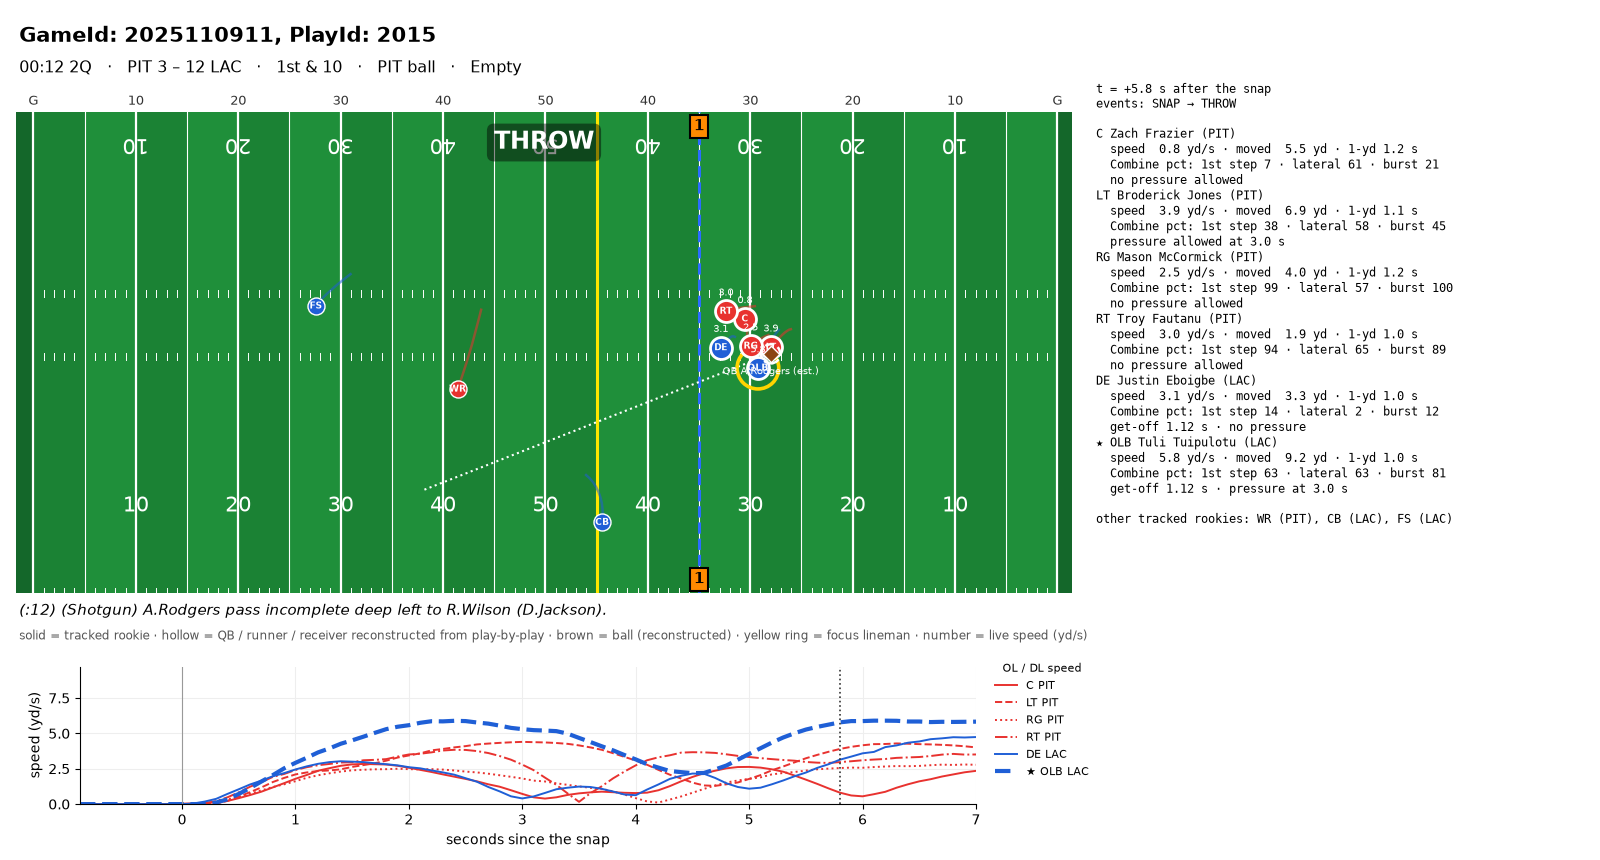

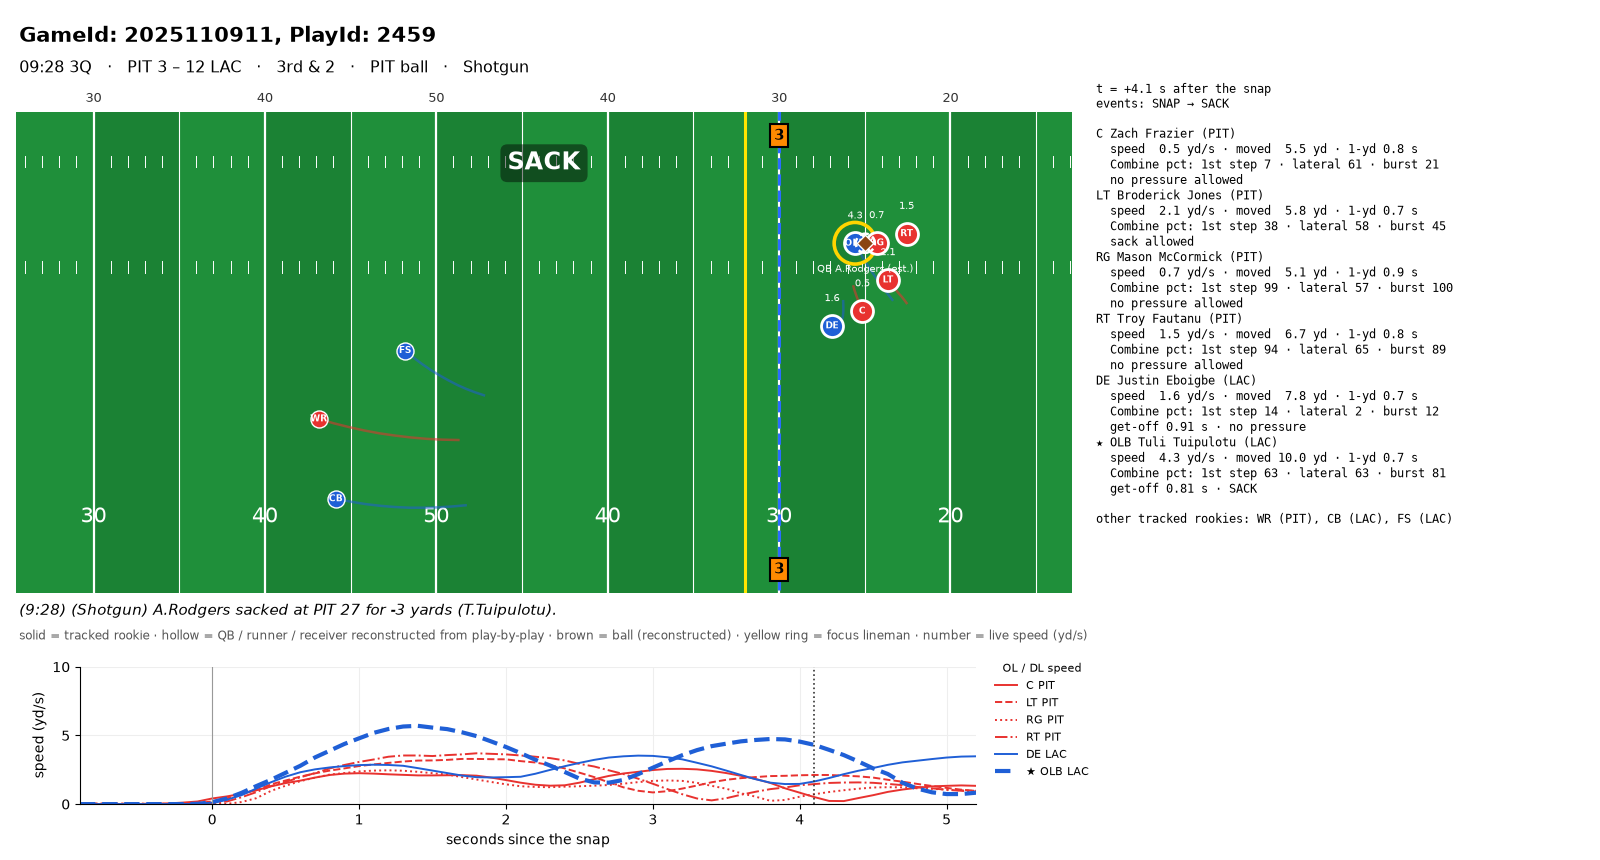

In [6]:
def draw_field(ax, P, xr=(-2, 122), yr=(-4.5, 58)):
    ax.set_xlim(*xr); ax.set_ylim(*yr); ax.set_aspect("equal"); ax.axis("off")
    ax.add_patch(patches.Rectangle((0, 0), 120, 53.3, fc=FIELD, zorder=0))
    for x0 in range(10, 110, 10): ax.add_patch(patches.Rectangle((x0, 0), 5, 53.3, fc=FIELD2, zorder=0))
    for x0 in (0, 110): ax.add_patch(patches.Rectangle((x0, 0), 10, 53.3, fc=ENDZONE, zorder=0))
    for x in range(10, 111, 5): ax.plot([x, x], [0, 53.3], color=LINE, lw=1.6 if x % 10 == 0 else 0.8, zorder=1)
    for x in range(11, 110):
        if x % 5:
            for y0, y1 in [(0.4, 1.0), (52.3, 52.9), (C.HASH_LO - 0.33, C.HASH_LO + 0.33), (C.HASH_HI - 0.33, C.HASH_HI + 0.33)]:
                ax.plot([x, x], [y0, y1], color=LINE, lw=0.7, zorder=1)
    ax.add_patch(patches.Rectangle((0, 0), 120, 53.3, fill=False, ec=LINE, lw=2.2, zorder=1))
    for x in range(20, 110, 10):
        n = x - 10 if x <= 60 else 110 - x
        ax.text(x, 9, str(n), color=LINE, fontsize=15, ha="center", va="center", zorder=1, clip_on=True)
        ax.text(x, 44.3, str(n), color=LINE, fontsize=15, ha="center", va="center", rotation=180, zorder=1, clip_on=True)
    left, right = (P["defense"], P["offense"]) if P["sign"] == -1 else (P["offense"], P["defense"])
    ax.text(5, 26.65, left, color="white", fontsize=17, rotation=90, ha="center", va="center", fontweight="bold", zorder=1, clip_on=True)
    ax.text(115, 26.65, right, color="white", fontsize=17, rotation=270, ha="center", va="center", fontweight="bold", zorder=1, clip_on=True)
    for gx in (0, 120): ax.plot([gx, gx], [C.HASH_LO + 0.5, C.HASH_HI - 0.5], color="#f2c200", lw=3, zorder=2)
    ax.plot([P["los"]] * 2, [0, 53.3], color=LOS_C, lw=2.2, ls="--", zorder=2)
    ax.plot([P["first_down"]] * 2, [0, 53.3], color=FD_C, lw=2.2, zorder=2)
    for yy in (yr[1] - 1.4, yr[0] + 1.4):                         # down marker at the edges of the view
        ax.text(P["los"], yy, str(int(P["ctx"].down)), ha="center", va="center", fontsize=11, fontweight="bold",
                bbox=dict(fc=MARK_C, ec="black", lw=1.5, boxstyle="square,pad=0.25"), zorder=3, clip_on=True)
    for x in range(10, 111, 10):                                  # yard labels above the view (readable at any zoom)
        if xr[0] <= x <= xr[1]:
            lab = "G" if x in (10, 110) else str(x - 10 if x <= 60 else 110 - x)
            ax.text(x, yr[1] + 0.4, lab, ha="center", va="bottom", fontsize=9, color="#333", clip_on=False)
    if "gap" in P["est"]:
        gp = P["est"]["gap"]
        ax.annotate("", xy=gp["end"], xytext=(P["los"], gp["y"]), zorder=2,
                    arrowprops=dict(arrowstyle="-|>", color="white", lw=1.6, ls="--", mutation_scale=14))

def mp4_play(P, name, fps=10, slow=0.5):
    f, info, times, est = P["f"], P["info"], P["times"], P["est"]
    fig = plt.figure(figsize=(16, 8.6), dpi=100)
    axf = fig.add_axes([0.01, 0.31, 0.66, 0.56]); axs = fig.add_axes([0.05, 0.065, 0.56, 0.16]); axp = fig.add_axes([0.685, 0.065, 0.31, 0.84])
    xr, yr = view_range(P, aspect=(0.66 * 16) / (0.56 * 8.6))
    draw_field(axf, P, xr, yr)
    t1, t2 = header(P)
    fig.text(0.012, 0.97, t1, fontsize=15, fontweight="bold", va="top"); fig.text(0.012, 0.93, t2, fontsize=11.5, va="top")
    fig.text(0.012, 0.298, str(P["ctx"].play_description)[:150], fontsize=10.5, style="italic", va="top")
    fig.text(0.012, 0.268, "solid = tracked rookie · hollow = QB / runner / receiver reconstructed from play-by-play · brown = ball (reconstructed) · "
             "yellow ring = focus lineman · number = live speed (yd/s)", fontsize=8.5, color="#555", va="top")
    axp.axis("off")
    n_side = {"Offense": 0, "Defense": 0}
    for nid, r in info[info.is_line].iterrows():
        n_side[r.side] += 1; d = f[f.nfl_id == nid]
        axs.plot(d.t, d.s, color=OFF if r.side == "Offense" else DEF, lw=3 if r.focus else 1.4,
                 ls=["-", "--", ":", "-."][(n_side[r.side] - 1) % 4], label=f"{'★ ' if r.focus else ''}{r.label} {r.team_abbr}")
    axs.set_xlim(times[0], times[-1]); axs.set_ylim(0, max(8, f.s.max() + 0.5)); axs.axvline(0, color="#999", lw=0.8)
    axs.set_xlabel("seconds since the snap"); axs.set_ylabel("speed (yd/s)"); axs.grid(color="#eee")
    axs.spines[["top", "right"]].set_visible(False)
    axs.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1.1), frameon=False, title="OL / DL speed", title_fontsize=8)
    cursor = axs.axvline(times[0], color="#333", lw=1.2, ls=":")
    art = {}
    for nid, r in info.iterrows():
        c = OFF if r.side == "Offense" else DEF
        art[nid] = dict(trail=axf.plot([], [], color=c, lw=1.8, alpha=0.55, zorder=3)[0],
                        dot=axf.scatter([], [], s=250 if r.is_line else 150, c=c, edgecolors="white", linewidths=2 if r.is_line else 1, zorder=5),
                        lab=axf.text(0, 0, "", color="white", fontsize=6.8, ha="center", va="center", fontweight="bold", zorder=6),
                        spd=axf.text(0, 0, "", color="white", fontsize=7.5, ha="center", va="bottom", zorder=6))
    ring = axf.scatter([], [], s=900, facecolors="none", edgecolors=FOCUS_C, linewidths=2.6, zorder=4)
    est_art = {k: (axf.scatter([], [], s=190, facecolors="none", edgecolors="white", linewidths=1.8, linestyle="--", zorder=5),
                   axf.text(0, 0, "", color="white", fontsize=7.5, ha="center", va="top", zorder=6))
               for k in ("qb", "runner", "receiver") if k in est}
    ball = axf.scatter([], [], s=70, marker="D", c=BALL_C, edgecolors="white", linewidths=1, zorder=7)
    throw = axf.plot([], [], color="white", lw=1.5, ls=":", zorder=3)[0]
    ban = axf.text(sum(xr) / 2, yr[1] - 3, "", color="white", fontsize=17, fontweight="bold", ha="center", va="center", zorder=8,
                   bbox=dict(fc=(0, 0, 0, 0.45), ec="none", boxstyle="round,pad=0.3"))
    panel = axp.text(0, 1, "", va="top", ha="left", fontsize=8.8, family="DejaVu Sans Mono", transform=axp.transAxes)
    def update(i):
        t = times[i]
        for nid in info.index:
            a = art[nid]; d = f[(f.nfl_id == nid) & (f.frame <= i)]; cur = d[d.frame == i]
            if cur.empty:
                a["dot"].set_offsets(np.empty((0, 2))); a["lab"].set_text(""); a["spd"].set_text(""); continue
            x, y = cur.x.iloc[0], cur.y.iloc[0]
            a["dot"].set_offsets([[x, y]]); a["lab"].set_position((x, y)); a["lab"].set_text(str(info.loc[nid, "label"])[:4])
            if info.loc[nid, "is_line"]: a["spd"].set_position((x, y + 1.3)); a["spd"].set_text(f"{cur.s.iloc[0]:.1f}")
            tr = d[d.frame > i - 10]; a["trail"].set_data(tr.x, tr.y)
        fr = f[(f.frame == i) & f.nfl_id.isin(info[info.focus].index)]
        ring.set_offsets(fr[["x", "y"]].values if len(fr) else np.empty((0, 2)))
        for k, (sc, tx) in est_art.items():
            x, y = est[k]["xy"][0][i], est[k]["xy"][1][i]
            if np.isnan(x): sc.set_offsets(np.empty((0, 2))); tx.set_text("")
            else: sc.set_offsets([[x, y]]); tx.set_position((x, y - 1.2)); tx.set_text(est[k]["label"])
        bx, by = est["ball"]["xy"][0][i], est["ball"]["xy"][1][i]
        ball.set_offsets(np.empty((0, 2)) if np.isnan(bx) else [[bx, by]])
        th = est.get("throw")
        throw.set_data(([th["start"][0], th["end"][0]], [th["start"][1], th["end"][1]]) if th and t >= th["t"] else ([], []))
        b = banner(P, t); ban.set_text(b); ban.set_visible(bool(b))
        cursor.set_xdata([t, t])
        panel.set_text("\n".join(panel_lines(P, t)).replace("<b>", "").replace("</b>", ""))
        return []
    anim = animation.FuncAnimation(fig, update, frames=len(times), interval=1000 / fps, blit=False)
    if HAVE_FFMPEG:
        out = ANIM_DIR / f"field_{name}.mp4"
        anim.save(out, writer=animation.FFMpegWriter(fps=int(fps * slow), bitrate=2800, codec="libx264", extra_args=["-pix_fmt", "yuv420p"]))
    else:
        out = ANIM_DIR / f"field_{name}.gif"; anim.save(out, writer=animation.PillowWriter(fps=int(fps * slow)))
    key_t = P["ev"].get("qb_sack", P["ev"].get("pass_forward", P["ev"].get("handoff", 0.0) + 1.0))
    update(int(np.argmin(np.abs(times - key_t)))); still = ANIM_DIR / f"field_{name}_snap.png"; fig.savefig(still, facecolor="white")
    plt.close(fig)
    return out, still

stills = []
for n, P in PLAYS.items():
    out, still = mp4_play(P, n); stills.append(still); print("saved", out.name, "and", still.name)
for s in stills[:2]: display(Image(str(s), width=1100))

In [7]:
summary = pd.DataFrame([dict(name=n, game_id=P["game_id"], play_id=P["play_id"], rookies_tracked=len(P["info"]),
                             focus=" ".join(f"{r.label} {r.display_name} ({r.team_abbr})" for _, r in P["info"][P["info"].focus].iterrows()),
                             linemen=", ".join(f"{r.label} {r.team_abbr}" for _, r in P["info"][P["info"].is_line].iterrows()),
                             description=str(P["ctx"].play_description)[:140], reconstructed="; ".join(P["notes"]),
                             html=f"play_viewer/{n}.html", video=f"animations/field_{n}.{'mp4' if HAVE_FFMPEG else 'gif'}")
                        for n, P in PLAYS.items()])
summary.to_csv(C.TABLE_DIR / "11_selected_plays.csv", index=False)
spark.stop()
summary[["name", "focus", "linemen", "description"]]

,name,focus,linemen,description
0,pressure_incomplete,OLB Tuli Tuipulotu (LAC),"C PIT, LT PIT, RG PIT, RT PIT, DE LAC, OLB LAC",(:12) (Shotgun) A.Rodgers pass incomplete deep...
1,sack,OLB Tuli Tuipulotu (LAC),"C PIT, LT PIT, RG PIT, RT PIT, DE LAC, OLB LAC",(9:28) (Shotgun) A.Rodgers sacked at PIT 27 fo...
2,pass_block_clean,RG Dominick Puni (SF),"LG SF, RG SF, DE ARI, DT ARI, NT ARI, OLB ARI",(2:08) M.Jones pass short left to C.McCaffrey ...
3,run_block_credit,C Zach Frazier (PIT),"C PIT, LG PIT, RT PIT, DE IND, DE IND, DT IND",(5:57) (Shotgun) J.Fields up the middle to PIT...
4,run_stuff,DT Darius Robinson (ARI),"LG SF, RG SF, DE ARI, DT ARI, NT ARI, OLB ARI",(1:06) C.McCaffrey right guard to ARZ 1 for no...
